# Worksheet 10

In [2]:
import numpy as np
from numpy import cos, sin, exp, sqrt, log
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import solve_ivp

### Question 2

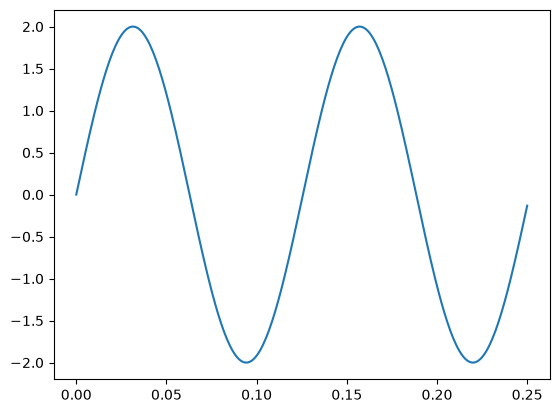

In [11]:
def v_in(t, a = 2, w = 50):
    return a * sin(w * t)

t0 = 0
tmax = 0.25

nn_ivp = 300
ts = np.linspace(t0, tmax, nn_ivp)
vs = v_in(ts)

plt.plot(ts, vs)

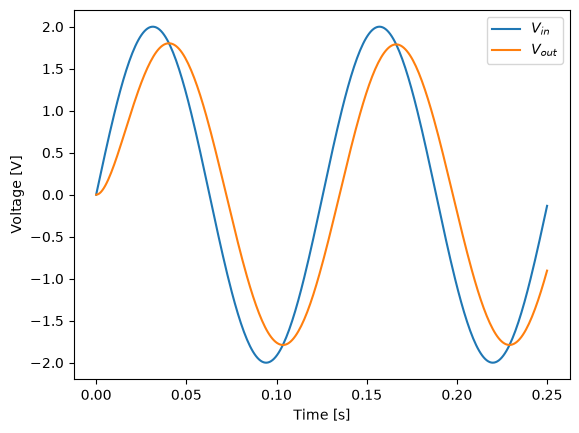

In [13]:
v_out0 = [0]

def v_out_func(t, v_out, r = 10e3, c = 1e-6):
    return (v_in(t) - v_out) / (r * c)

t_span = ts[0], ts[-1]
sol = solve_ivp(v_out_func, t_span, v_out0, t_eval = ts)
ys = sol.y[0] # solution is 1st and only row

plt.plot(ts, vs, label = '$V_{in}$')
plt.plot(ts, ys, label = '$V_{out}$')
plt.xlabel('Time [s]')
plt.ylabel('Voltage [V]')
plt.legend()
plt.show()

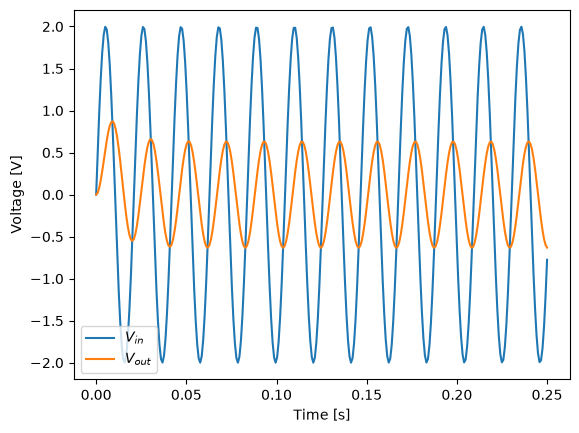

In [15]:
vs = v_in(ts, w = 300)

def v_out_func(t, v_out, r = 10e3, c = 1e-6):
    return (v_in(t, w = 300) - v_out) / (r * c)

sol = solve_ivp(v_out_func, t_span, v_out0, t_eval = ts)
ys = sol.y[0] # solution is 1st and only row

plt.plot(ts, vs, label = '$V_{in}$')
plt.plot(ts, ys, label = '$V_{out}$')
plt.xlabel('Time [s]')
plt.ylabel('Voltage [V]')
plt.legend()
plt.show()

### Question 3

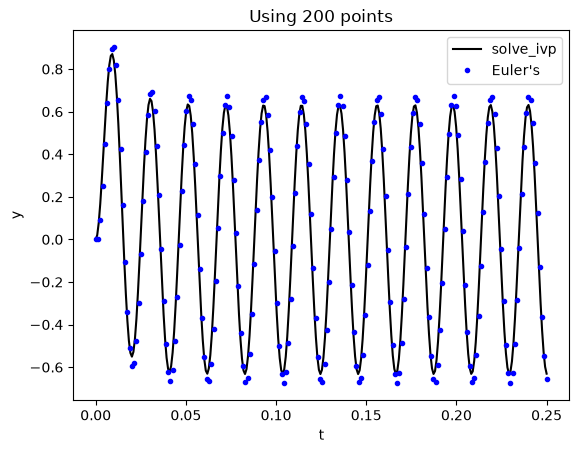

In [33]:
nne = 200

# solve with euler
h = (tmax - t0) / (nne - 1)
ts_eul = np.linspace(t0, tmax, nne)
ys_eul = np.zeros_like(ts_eul)
ys_eul[0] = v_out0[0]

for j in range(nne - 1):
    tj = ts_eul[j]
    yj = ys_eul[j]
    ys_eul[j + 1] = yj + h * v_out_func(tj, yj)


plt.title(f'Using {nne} points')
plt.plot(ts, ys, label = 'solve_ivp', color = 'k')
plt.plot(ts_eul, ys_eul, 'b.', label = "Euler's")
plt.legend()
plt.xlabel('t')
plt.ylabel('y')
plt.show()

### Question 4

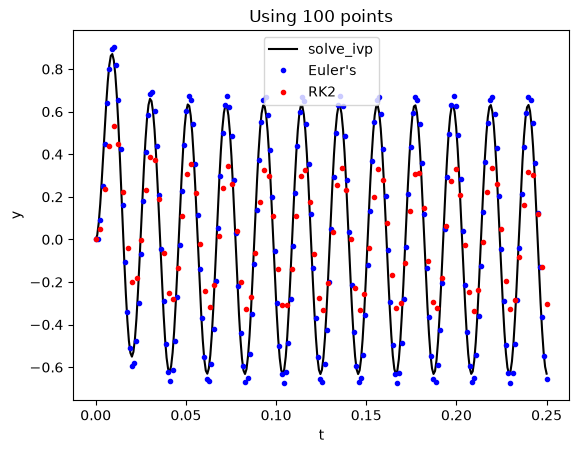

In [39]:
nne = 100

# solve with RK2
ts_rk2 = np.linspace(t0, tmax, nne)
ys_rk2 = np.zeros_like(ts_rk2)
ys_rk2[0] = v_out0[0]

for j in range(nne - 1):
    tj = ts_rk2[j]
    yj = ys_rk2[j]
    k1 = h * v_out_func(tj, yj)
    k2 = h * v_out_func(tj + h/2, yj + k1 / 2)
    ys_rk2[j + 1] = yj + k2

plt.title(f'Using {nne} points')
plt.plot(ts, ys, label = 'solve_ivp', color = 'k')
plt.plot(ts_eul, ys_eul, 'b.', label = "Euler's")
plt.plot(ts_rk2, ys_rk2, 'r.', label = "RK2")
plt.legend()
plt.xlabel('t')
plt.ylabel('y')
plt.show()

### Question 5

In [ ]:
a = 1
b = 0.5
g = 0.5
d = 2

def rabbit(r, f):
    return a * r - b * r * f
def fox(r, f):
    return g * r * f - d * f

In [42]:
r0 = [2]
f0 = [2]

t = np.linspace(0, 15, 200)

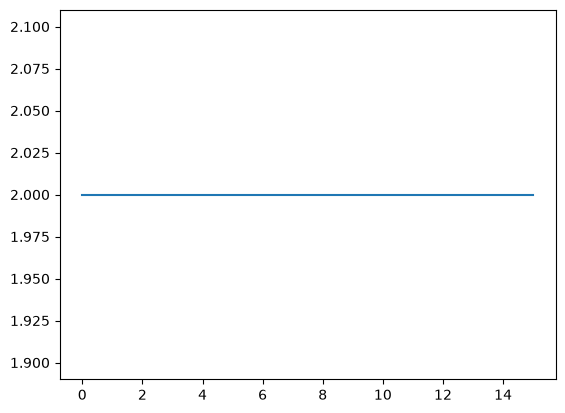

In [44]:
t_span = t[0], t[-1]
sol = solve_ivp(rabbit, t_span, r0, t_eval = t)
r = sol.y[0] # solution is 1st and only row
plt.plot(t, r)